Problem 4:

Question: For the Diagnosis column in data.csv, implement imputation with:

Constant strategy using 'Missing' string

Add a missing indicator column

Write the complete code using SimpleImputer.


In [7]:
import pandas as pd
import numpy as np
from sklearn.impute import SimpleImputer
from sklearn.model_selection import train_test_split
import seaborn as sns
df=pd.read_csv('data.csv')
df.head(5)

,Age,Income,Salary,Rating,Annual_Income,Customer_Support_Calls,House_Price,Square_Feet,Temperature,City,Product_Type,Location,Diagnosis,Cabin,Embarked,Gender,Target,Price_Target
0,40.0,9165.0,55361,2.9,NaN,NaN,495310.0,2091,15.1,Dhaka,Unknown,A,NaN,NaN,S,Male,0,280.32
1,33.0,5522.0,48717,NaN,52868.0,1.0,368695.0,1504,28.3,Chittagong,C,C,Type3,NaN,S,Female,1,314.83
2,42.0,50589.0,64787,3.1,79526.0,2.0,453606.0,2052,22.0,Sylhet,A,C,Type1,NaN,C,Female,0,252.43
3,53.0,61289.0,80106,3.6,107581.0,1.0,359753.0,2075,22.7,Rajshahi,C,B,Type2,NaN,S,Female,0,239.21
4,32.0,1604.0,31872,4.0,89654.0,1.0,228869.0,1248,NaN,Rajshahi,A,C,Type2,NaN,S,Female,0,179.51


In [8]:
df.isnull().sum()

Age                       180
Income                    150
Salary                      0
Rating                     80
Annual_Income             120
Customer_Support_Calls     80
House_Price               100
Square_Feet                 0
Temperature                50
City                       50
Product_Type                0
Location                    0
Diagnosis                 220
Cabin                     680
Embarked                    2
Gender                      0
Target                      0
Price_Target                0
dtype: int64

<Axes: xlabel='Diagnosis', ylabel='count'>

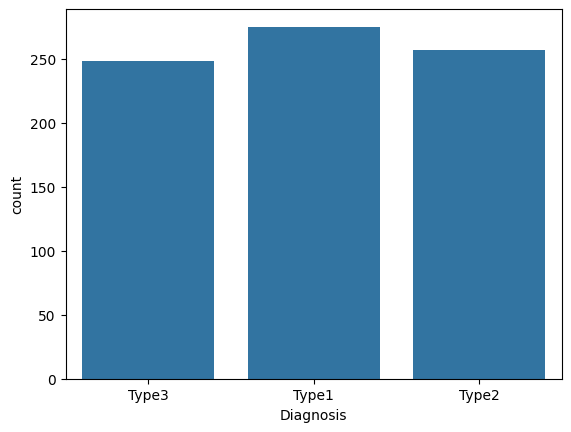

In [13]:
sns.countplot(x=df['Diagnosis'])

In [10]:
X=df.drop('Target',axis=1)
y=df['Target']

In [11]:
X_train,X_test,y_train,y_test=train_test_split(X,y,test_size=0.2,random_state=42)
print(X_train.shape)
print(X_test.shape)
print(y_train.shape)
print(y_test.shape)

(800, 17)
(200, 17)
(800,)
(200,)


In [12]:
X_train

,Age,Income,Salary,Rating,Annual_Income,Customer_Support_Calls,House_Price,Square_Feet,Temperature,City,Product_Type,Location,Diagnosis,Cabin,Embarked,Gender,Price_Target
29,NaN,20541.0,46632,4.2,30172.0,1.0,111387.0,1866,32.5,Chittagong,B,B,Type1,NaN,S,Male,231.94
535,35.0,46050.0,71684,2.8,72318.0,2.0,289801.0,2067,28.2,Dhaka,B,B,NaN,NaN,Q,Female,228.30
695,31.0,8652.0,85790,1.4,NaN,4.0,227513.0,1812,24.2,NaN,C,C,NaN,NaN,C,Male,266.84
557,29.0,93707.0,52109,4.5,100627.0,1.0,191999.0,1510,24.5,Dhaka,A,B,NaN,NaN,S,Female,221.75
836,53.0,41021.0,61257,1.9,52816.0,1.0,106457.0,1438,21.8,Sylhet,B,C,NaN,NaN,S,Female,261.28
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
106,57.0,1868.0,53454,4.1,55001.0,3.0,NaN,1115,27.2,Chittagong,A,A,Type1,NaN,S,Female,161.48
270,52.0,55063.0,52856,3.1,111554.0,2.0,162436.0,2028,23.6,Sylhet,B,A,NaN,NaN,C,Female,303.58
860,37.0,7655.0,54442,3.7,40181.0,5.0,231088.0,1142,21.6,Chittagong,Unknown,A,Type1,NaN,S,Female,327.19
435,35.0,48894.0,50286,4.1,96119.0,3.0,NaN,1722,24.5,Chittagong,A,A,Type2,NaN,S,Male,311.50


In [14]:
missing_string=SimpleImputer(missing_values=np.nan,strategy='constant',add_indicator=True)
missing_string.fit(X_train[['Diagnosis']])
X_train[['Diagnosis','missing_indicator']]=missing_string.transform(X_train[['Diagnosis']])
X_test[['Diagnosis','missing_indicator']]=missing_string.transform(X_test[['Diagnosis']])
X_train.isnull().sum()

Age                       139
Income                    126
Salary                      0
Rating                     66
Annual_Income              97
Customer_Support_Calls     62
House_Price                83
Square_Feet                 0
Temperature                42
City                       38
Product_Type                0
Location                    0
Diagnosis                   0
Cabin                     545
Embarked                    2
Gender                      0
Price_Target                0
missing_indicator           0
dtype: int64

In [15]:
X_test.isnull().sum()

Age                        41
Income                     24
Salary                      0
Rating                     14
Annual_Income              23
Customer_Support_Calls     18
House_Price                17
Square_Feet                 0
Temperature                 8
City                       12
Product_Type                0
Location                    0
Diagnosis                   0
Cabin                     135
Embarked                    0
Gender                      0
Price_Target                0
missing_indicator           0
dtype: int64

In [16]:
X_train

,Age,Income,Salary,Rating,Annual_Income,Customer_Support_Calls,House_Price,Square_Feet,Temperature,City,Product_Type,Location,Diagnosis,Cabin,Embarked,Gender,Price_Target,missing_indicator
29,NaN,20541.0,46632,4.2,30172.0,1.0,111387.0,1866,32.5,Chittagong,B,B,Type1,NaN,S,Male,231.94,False
535,35.0,46050.0,71684,2.8,72318.0,2.0,289801.0,2067,28.2,Dhaka,B,B,missing_value,NaN,Q,Female,228.30,True
695,31.0,8652.0,85790,1.4,NaN,4.0,227513.0,1812,24.2,NaN,C,C,missing_value,NaN,C,Male,266.84,True
557,29.0,93707.0,52109,4.5,100627.0,1.0,191999.0,1510,24.5,Dhaka,A,B,missing_value,NaN,S,Female,221.75,True
836,53.0,41021.0,61257,1.9,52816.0,1.0,106457.0,1438,21.8,Sylhet,B,C,missing_value,NaN,S,Female,261.28,True
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
106,57.0,1868.0,53454,4.1,55001.0,3.0,NaN,1115,27.2,Chittagong,A,A,Type1,NaN,S,Female,161.48,False
270,52.0,55063.0,52856,3.1,111554.0,2.0,162436.0,2028,23.6,Sylhet,B,A,missing_value,NaN,C,Female,303.58,True
860,37.0,7655.0,54442,3.7,40181.0,5.0,231088.0,1142,21.6,Chittagong,Unknown,A,Type1,NaN,S,Female,327.19,False
435,35.0,48894.0,50286,4.1,96119.0,3.0,NaN,1722,24.5,Chittagong,A,A,Type2,NaN,S,Male,311.50,False
